# Population Pyramid

**Family:** Distribution &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Basic

> *Distribution:* Show values in a dataset and how often they occur; the shape (skew, spread, gaps) is the story.

## Design purpose

Back-to-back horizontal histograms of age bands, with males on one side and females on the other. A population's age structure (growing, stable or ageing) shows at a glance.

## When to use

- Show the age and sex structure of a population
- Compare two groups across the same ordered bins

## Avoid when

- The bins are not ordered
- Comparing many populations (use small multiples or overlay outlines)

## Alternatives

- Spine chart
- Overlaid outline pyramids for two years

## Design tips

- Use the same scale on both sides and label the ticks with absolute values
- Use percent of total rather than counts when comparing populations of different size
- Keep the bands in age order with the youngest at the bottom

## Example

Age structure of a fictional ageing population (percent of total), in 5-year bands.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

### Data

In [2]:
bands = [f"{a}–{a + 4}" for a in range(0, 90, 5)] + ["90+"]
age_mid = np.arange(2.5, 95, 5)
base = np.exp(-((age_mid - 48) / 30) ** 2) * 4 + 1.2
base[-4:] *= np.array([0.8, 0.55, 0.3, 0.12])
male = base * (1.02 - age_mid / 400)
female = base * (0.98 + age_mid / 500)
tot = male.sum() + female.sum()
df = pd.DataFrame({"band": bands, "male": male / tot * 100, "female": female / tot * 100})
df.round(2).tail()

,band,male,female
14,70–74,2.30,3.09
15,75–79,1.52,2.08
16,80–84,0.86,1.20
17,85–89,0.39,0.56
18,90+,0.13,0.19


### Plot

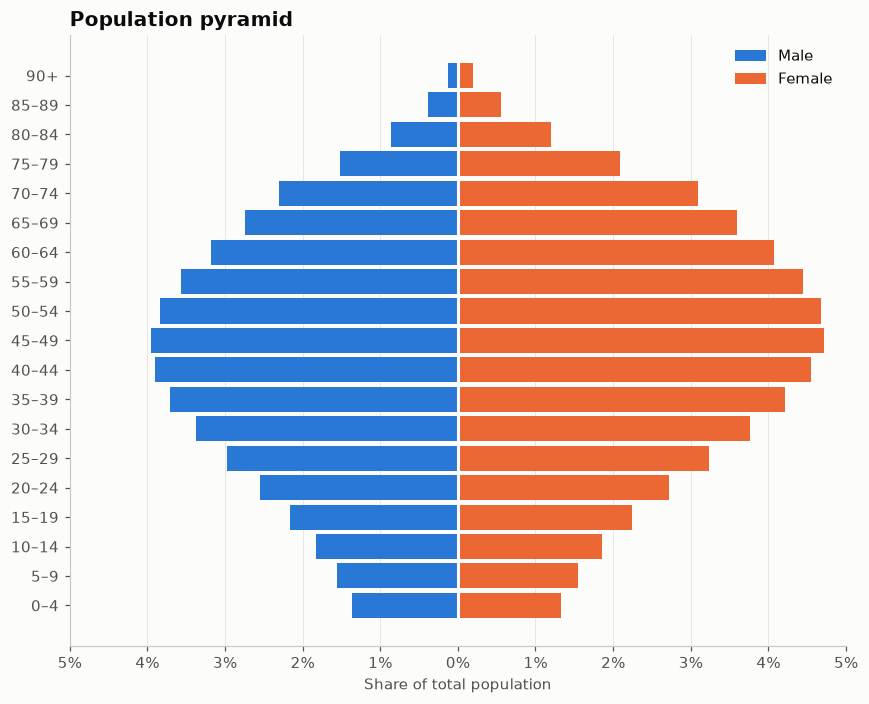

In [3]:
fig, ax = plt.subplots(figsize=(8, 6.5))
ax.barh(df["band"], -df["male"], color=PALETTE[0], height=0.85, label="Male")
ax.barh(df["band"], df["female"], color=PALETTE[1], height=0.85, label="Female")
ax.axvline(0, color="#fcfcfb", linewidth=2)
lim = 5
ticks = np.arange(-5, 6, 1)
ax.set_xticks(ticks, [f"{abs(t)}%" for t in ticks])
ax.set_xlim(-lim, lim)
ax.set_xlabel("Share of total population")
ax.set_title("Population pyramid")
ax.grid(axis="y", visible=False)
ax.legend(loc="upper right")
fig.tight_layout()
plt.show()

## How to read it

Each row is an age band, with males to the left and females to the right. The bulge in middle age and narrow base point to an ageing population with low birth rates. Women outnumber men from the late teens on, and the gap widens with age.

---
Standalone script: [`population_pyramid.py`](population_pyramid.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)